# Question 2: analysis of the saved Colab results
**Student ID:** 23k-0078

The GPU training notebook is `Assignment_Beta_Question_no_2_23k-0078.ipynb`. This notebook trains nothing. It reads the files that run saved in `../assignment_beta_q2_fixed` and works out the extra figures used in the report: significance tests, the company test breakdown, the merge check and the failures. It also reads the first run in `../assignment_beta_q2`, to compare the two.

In [1]:
import json, math
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

NEW, OLD = Path("../assignment_beta_q2_fixed"), Path("../assignment_beta_q2")
NAMES = ["Baseline", "LoRA_r4", "LoRA_r8", "LoRA_r16", "LoRA_r32", "QLoRA_r8", "DoRA_r8", "AdaLoRA_r8"]
preds = {n: json.loads((NEW / f"{n}_predictions.json").read_text(encoding="utf-8")) for n in NAMES}
stats = {n: json.loads((NEW / f"{n}.json").read_text()) for n in NAMES}
split = json.loads((NEW / "data_split.json").read_text(encoding="utf-8"))
old_split = json.loads((OLD / "data_split.json").read_text(encoding="utf-8"))
merge = json.loads((NEW / "merge_check.json").read_text())
merge_outputs = json.loads((NEW / "merge_outputs.json").read_text(encoding="utf-8"))

def first_json(text):
    i = text.find("{")
    if i < 0:
        return None
    try:
        obj, _ = json.JSONDecoder().raw_decode(text, i)
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def right(row, full=False):
    gold, obj = json.loads(row["gold"]), first_json(row["output"])
    return bool(obj) and obj.get("name") == gold["name"] and (not full or obj.get("arguments") == gold["arguments"])

tool = {n: [right(r) for r in preds[n]["test"]] for n in NAMES}
full = {n: [right(r, True) for r in preds[n]["test"]] for n in NAMES}
for n in NAMES:
    assert abs(sum(tool[n]) / 200 - stats[n]["tool_accuracy"]) < 1e-9 and abs(sum(full[n]) / 200 - stats[n]["full_match"]) < 1e-9
print("Tool accuracy and full match recomputed from raw outputs match the Colab summary for all 8 runs.")

Tool accuracy and full match recomputed from raw outputs match the Colab summary for all 8 runs.


## Was the comparison between runs fair?
The test sets must be the same, and the untuned model must behave the same, or the two runs cannot be compared.

In [2]:
same_test = split["test"] == old_split["test"] and split["no_call_test"] == old_split["no_call_test"]
old_base = json.loads((OLD / "Baseline_predictions.json").read_text(encoding="utf-8"))
base_same = {k: sum(a["output"] == b["output"] for a, b in zip(old_base[k], preds["Baseline"][k])) for k in ("test", "no_call", "company")}
old_users = {e["user"] for e in old_split["train"]}
overlap = sum(e["user"] in old_users for e in split["train"])
leaked = {e["user"] for e in split["train"]} & {e["user"] for e in split["test"] + split["no_call_test"]}
print("Test sets identical:", same_test)
print("Base model identical outputs:", base_same)
print("Label fix:", split["meta"])
print("Training examples also in the first run:", overlap, "of", len(split["train"]), "| test examples in training:", len(leaked))
print("Training kinds:", Counter(e["kind"] for e in split["train"]))
comparison = []
for n in ("LoRA_r8", "QLoRA_r8", "DoRA_r8", "AdaLoRA_r8"):
    old = json.loads((OLD / f"{n}.json").read_text())
    new = stats[n]
    comparison.append({"run": n, "tool_first": old["tool_accuracy"], "tool_second": new["tool_accuracy"], "full_first": old["full_match"], "full_second": new["full_match"],
                       "json_first": old["json_valid"], "json_second": new["json_valid"]})
print(pd.DataFrame(comparison).to_string(index=False))

Test sets identical: True
Base model identical outputs: {'test': 200, 'no_call': 50, 'company': 50}
Label fix: {'old_no_call_train': 270, 'old_no_call_train_really_calls': 108, 'train_calls_announced_first': 432}
Training examples also in the first run: 1376 of 1800 | test examples in training: 0
Training kinds: Counter({'call': 1530, 'no_call': 270})
       run  tool_first  tool_second  full_first  full_second  json_first  json_second
   LoRA_r8       0.690        0.995       0.650        0.935         136          199
  QLoRA_r8       0.735        0.995       0.685        0.930         143          199
   DoRA_r8       0.690        0.995       0.650        0.935         136          199
AdaLoRA_r8       0.825        0.975       0.745        0.895         148          194


## False calls on the no-call test
The notebook identified 7 of the 50 messages as announced calls from Glaive's conversation structure, leaving 43. In the first run I had reviewed the same 50 by hand and marked 9 as complete requests, so this also checks that review.

In [3]:
ANNOUNCED = set(split["announced_in_no_call_test"])
HAND_COMPLETE = {1, 5, 12, 19, 24, 33, 34, 37, 49}
index = {i for i, e in enumerate(split["no_call_test"]) if e["user"] in ANNOUNCED}
print("Announced:", sorted(index), "| marked complete by hand but not announced:", sorted(HAND_COMPLETE - index), "| announced but not marked:", sorted(index - HAND_COMPLETE))
calls = {n: {i for i, r in enumerate(preds[n]["no_call"]) if first_json(r["output"]) is not None} for n in NAMES}
review = pd.DataFrame([{"run": n, "calls_of_50": len(calls[n]), "false_of_43": len(calls[n] - index), "false_of_41_by_hand": len(calls[n] - HAND_COMPLETE)} for n in NAMES])
print(review.to_string(index=False))
for i in sorted(HAND_COMPLETE - index):
    print(f"[{i}]", split["no_call_test"][i]["user"][:90], "->", preds["QLoRA_r8"]["no_call"][i]["output"][:90])
print("Invented by the base model:")
for i in (2, 15, 20, 27):
    print(" ", split["no_call_test"][i]["user"][:50], "->", preds["Baseline"]["no_call"][i]["output"][:100])

Announced: [5, 12, 19, 24, 34, 37, 49] | marked complete by hand but not announced: [1, 33] | announced but not marked: []
       run  calls_of_50  false_of_43  false_of_41_by_hand
  Baseline           40           33                   31
   LoRA_r4            9            2                    0
   LoRA_r8            9            2                    0
  LoRA_r16            9            2                    0
  LoRA_r32            9            2                    0
  QLoRA_r8            9            2                    0
   DoRA_r8            9            2                    0
AdaLoRA_r8            9            2                    0
[1] Hi, I have a dress that I bought for $100. There's a 20% discount on it. Can you tell me h -> {"name": "calculate_discount", "arguments": {"original_price": 100, "discount_percentage":
[33] I am looking for books on artificial intelligence. Can you help me find some? -> {"name": "search_books", "arguments": {"keywords": "artificial intelligence"}}
I

## Paired exact tests
Each test uses only the messages where the two runs disagree. `a` counts messages only the first run got right, and `b` those only the second got right.

In [4]:
def mcnemar(x, y):
    a = sum(p and not q for p, q in zip(x, y))
    b = sum(q and not p for p, q in zip(x, y))
    p = min(1.0, 2 * sum(math.comb(a + b, i) for i in range(min(a, b) + 1)) / 2 ** (a + b)) if a + b else 1.0
    return {"a": a, "b": b, "p": p}

company_right = {n: [bool(first_json(r["output"])) and first_json(r["output"]).get("name") == r["gold"] for r in preds[n]["company"] if r["gold"]] for n in NAMES}
clean = [i for i in range(50) if i not in index]
no_false = {n: [i not in calls[n] for i in clean] for n in NAMES}
pairs = [("Baseline", "LoRA_r8"), ("Baseline", "QLoRA_r8"), ("LoRA_r8", "QLoRA_r8"), ("LoRA_r8", "AdaLoRA_r8"), ("QLoRA_r8", "AdaLoRA_r8"), ("LoRA_r4", "LoRA_r8"), ("LoRA_r8", "LoRA_r16"), ("LoRA_r16", "LoRA_r32"), ("LoRA_r4", "LoRA_r32"), ("LoRA_r8", "LoRA_r32")]
tests = {}
for a, b in pairs:
    tests[f"{a} vs {b}"] = {"tool": mcnemar(tool[a], tool[b]), "full": mcnemar(full[a], full[b]), "company": mcnemar(company_right[a], company_right[b]), "no_false": mcnemar(no_false[a], no_false[b])}
print(pd.DataFrame({k: {m: f"{v[m]['a']}/{v[m]['b']} p={v[m]['p']:.4f}" for m in v} for k, v in tests.items()}).T.to_string())

                                tool           full        company       no_false
Baseline vs LoRA_r8     1/2 p=1.0000  4/11 p=0.1185  10/1 p=0.0117  0/31 p=0.0000
Baseline vs QLoRA_r8    1/2 p=1.0000  5/11 p=0.2101   5/1 p=0.2188  0/31 p=0.0000
LoRA_r8 vs QLoRA_r8     0/0 p=1.0000   2/1 p=1.0000   0/5 p=0.0625   0/0 p=1.0000
LoRA_r8 vs AdaLoRA_r8   5/1 p=0.2188  11/3 p=0.0574   1/8 p=0.0391   0/0 p=1.0000
QLoRA_r8 vs AdaLoRA_r8  5/1 p=0.2188  11/4 p=0.1185   2/4 p=0.6875   0/0 p=1.0000
LoRA_r4 vs LoRA_r8      0/0 p=1.0000   1/1 p=1.0000   1/5 p=0.2188   0/0 p=1.0000
LoRA_r8 vs LoRA_r16     0/1 p=1.0000   2/2 p=1.0000   0/3 p=0.2500   0/0 p=1.0000
LoRA_r16 vs LoRA_r32    0/0 p=1.0000   0/2 p=0.5000   3/0 p=0.2500   0/0 p=1.0000
LoRA_r4 vs LoRA_r32     0/1 p=1.0000   3/5 p=0.7266   2/6 p=0.2891   0/0 p=1.0000
LoRA_r8 vs LoRA_r32     0/1 p=1.0000   2/4 p=0.6875   1/1 p=1.0000   0/0 p=1.0000


## Section 3: rank

In [5]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

rows = []
for r in (4, 8, 16, 32):
    n = f"LoRA_r{r}"
    s = stats[n]
    lo, hi = wilson(sum(tool[n]), 200)
    c = sum(company_right[n])
    c_lo, c_hi = wilson(c, 40)
    rows.append({"rank": r, "trainable": s["trainable_parameters"], "percent": s["trainable_percent"], "adapter_mb": (NEW / "adapters" / n / "adapter_model.safetensors").stat().st_size / 1e6,
                 "peak_gb": s["peak_train_memory_gb"], "minutes": s["train_minutes"], "json_valid": s["json_valid"], "tool": s["tool_accuracy"], "tool_lo": lo, "tool_hi": hi,
                 "full": s["full_match"], "false_43": len(calls[n] - index), "company": c, "company_lo": c_lo, "company_hi": c_hi})
ranks = pd.DataFrame(rows)
print(ranks.round(3).to_string(index=False))

 rank  trainable  percent  adapter_mb  peak_gb  minutes  json_valid  tool  tool_lo  tool_hi  full  false_43  company  company_lo  company_hi
    4    1089536    0.071       4.388    6.539   11.254         199 0.995    0.972    0.999 0.935         2       25       0.470       0.758
    8    2179072    0.141       8.746    6.551   11.231         199 0.995    0.972    0.999 0.935         2       29       0.572       0.839
   16    4358144    0.282      17.462    6.576   11.252         200 1.000    0.981    1.000 0.935         2       32       0.652       0.895
   32    8716288    0.561      34.895    6.625   11.262         200 1.000    0.981    1.000 0.945         2       29       0.572       0.839


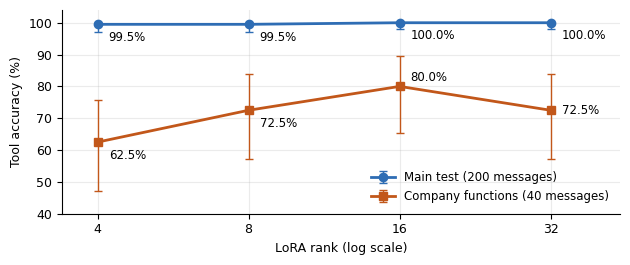

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 2.75))
x = ranks["rank"]
y1, y2 = 100 * ranks.tool, 100 * ranks.company / 40
ax.errorbar(x, y1, yerr=[y1 - 100 * ranks.tool_lo, 100 * ranks.tool_hi - y1], color="#2E6DB4", marker="o", markersize=6, linewidth=2, capsize=3, elinewidth=1, label="Main test (200 messages)")
ax.errorbar(x, y2, yerr=[y2 - 100 * ranks.company_lo, 100 * ranks.company_hi - y2], color="#C2571A", marker="s", markersize=6, linewidth=2, capsize=3, elinewidth=1, label="Company functions (40 messages)")
for a, v in zip(x, y1):
    ax.annotate(f"{v:.1f}%", (a, v), textcoords="offset points", xytext=(8, -12), fontsize=8.5)
for a, v, offset in zip(x, y2, [(8, -12), (8, -12), (8, 4), (8, -3)]):
    ax.annotate(f"{v:.1f}%", (a, v), textcoords="offset points", xytext=offset, fontsize=8.5)
ax.set_xscale("log", base=2)
ax.set_xticks(x, [str(r) for r in x])
ax.minorticks_off()
ax.set_xlim(3.4, 44)
ax.set_ylim(40, 104)
ax.set_xlabel("LoRA rank (log scale)", fontsize=9)
ax.set_ylabel("Tool accuracy (%)", fontsize=9)
ax.tick_params(labelsize=9)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=8.5, frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig("q2_rank_plot.png", dpi=200)
plt.show()

## Where AdaLoRA put its rank

In [7]:
cfg = json.loads((NEW / "adapters" / "AdaLoRA_r8" / "adapter_config.json").read_text())
mods = {}
for key, mask in cfg["rank_pattern"].items():
    mods.setdefault(key.split(".lora_")[0].split(".")[-1], []).append(sum(mask))
alloc = {m: round(sum(v) / len(v), 1) for m, v in mods.items()}
print("Start", cfg["init_r"], "target", cfg["target_r"], alloc, "| effective parameters", stats["AdaLoRA_r8"]["effective_trainable"])

Start 12 target 8 {'k_proj': 11.5, 'o_proj': 6.3, 'q_proj': 2.5, 'v_proj': 11.7} | effective parameters 1923968


## Merge check
On the first 50 test examples for accuracy and speed, and on the no-call test for false calls.

In [8]:
merge_table = pd.DataFrame(merge)
print(merge_table.round(3).to_string(index=False))
sample = split["test"][:50]
kinds = {}
for name, outs in merge_outputs.items():
    k = Counter()
    for ex, m in zip(sample, outs["merged"]):
        obj = first_json(m)
        k["right_tool" if obj and obj.get("name") == ex["name"] else "no_call" if not obj else "other"] += 1
    kinds[name] = dict(k)
print("Merged, on 50 messages:", kinds)
q = merge_outputs["QLoRA_r8"]
shown = 0
for ex, a, m in zip(sample, q["attached"], q["merged"]):
    if not first_json(m) and shown < 3:
        shown += 1
        print("U:", ex["user"][:75], "\n  attached:", a[:80], "\n  merged:", m[:100].replace("\n", " "))
first_merge = json.loads((OLD / "merge_check.json").read_text())
print("First run, QLoRA:", [(m["state"], m["tool_accuracy"], m.get("same_output_as_unmerged")) for m in first_merge if m["run"] == "QLoRA"])

     run            state  tokens_per_second  peak_memory_gb  tool_accuracy  no_call_false_calls_clean  same_output_as_training_run  same_output_as_unmerged
 LoRA_r8 adapter attached             72.251           3.159           1.00                          2                          1.0                      NaN
 LoRA_r8           merged            110.928           3.151           1.00                          2                          NaN                     1.00
QLoRA_r8 adapter attached             51.881           1.356           1.00                          2                          1.0                      NaN
QLoRA_r8           merged             64.710           1.348           0.86                          9                          NaN                     0.46
 DoRA_r8 adapter attached             40.579           3.162           1.00                          2                          1.0                      NaN
 DoRA_r8           merged            109.213           3.1

## Company scenario

In [9]:
ROMAN_URDU = {"Mera order ORD-2290 kab tak aayega?", "Mujhe ORD-5128 ka refund chahiye, product kharab hai.", "Mera parcel TRK-120983 abhi kahan hai?", "Kisi insaan se baat karwa dein please."}
rows = []
for n in NAMES:
    s, kind, by = stats[n], Counter(), Counter()
    urdu = 0
    for r in preds[n]["company"]:
        if not r["gold"]:
            continue
        obj = first_json(r["output"])
        ok = bool(obj) and obj.get("name") == r["gold"]
        by[r["gold"]] += ok
        urdu += ok and r["user"] in ROMAN_URDU
        kind["right" if ok else "wrong_tool" if obj else "no_call"] += 1
    rows.append({"run": n, "right_40": kind["right"], "wrong_tool": kind["wrong_tool"], "no_call": kind["no_call"], "id_29": round(s["company_identifier_accuracy"] * 29), "roman_urdu_4": urdu,
                 "escalate_10": by["escalate_to_human"], "refunds": s["unauthorized_refunds"], "unnecessary": s["unnecessary_calls"]})
company = pd.DataFrame(rows)
print(company.to_string(index=False))
print("\nQLoRA r = 8, what went wrong:")
for r in preds["QLoRA_r8"]["company"]:
    obj = first_json(r["output"])
    if r["gold"] and (not obj or obj.get("name") != r["gold"]):
        print(" ", r["user"][:66], "->", r["output"][:95].replace("\n", " "))
print("\nFirst company message:", preds["QLoRA_r8"]["company"][0]["user"], "->", preds["QLoRA_r8"]["company"][0]["output"])

       run  right_40  wrong_tool  no_call  id_29  roman_urdu_4  escalate_10  refunds  unnecessary
  Baseline        38           2        0     28             4           10        0            0
   LoRA_r4        25           1       14     19             1            5        0            0
   LoRA_r8        29           1       10     23             1            5        0            0
  LoRA_r16        32           1        7     24             1            7        0            0
  LoRA_r32        29           1       10     23             1            5        0            0
  QLoRA_r8        34           1        5     26             2            7        0            0
   DoRA_r8        29           1       10     23             1            5        0            0
AdaLoRA_r8        36           2        2     27             2            9        0            0

QLoRA r = 8, what went wrong:
  I just want to know if ORD-8815 is on its way or still being packe -> {"name": "track

## Failures of the model I would ship, QLoRA r = 8
The Colab notebook wrote failures for LoRA r = 32, the top run by its selection rule. The report ships QLoRA r = 8, so it uses that model's failures.

In [10]:
best = preds["QLoRA_r8"]["test"]
failures = pd.DataFrame([{"index": i, **r} for i, r in enumerate(best) if r["error"]])
failures.to_csv("shipped_model_failures.csv", index=False, encoding="utf-8")
counts = Counter(failures.error)
print(len(failures), "failures:", counts.most_common())
print("Wrong-tool errors on the 200 examples, by run:", {n: sum(r["error"] == "wrong_tool" for r in preds[n]["test"]) for n in NAMES})
print("Most functions offered in one test example:", max(len(e["functions"]) for e in split["test"]))
CHOSEN = [194, 33, 86, 153, 1]
for i in CHOSEN:
    r = best[i]
    print(f"\n[{i}] {r['error']}\nU: {r['user']}\nG: {r['gold']}\nO: {r['output']}")

14 failures: [('wrong_argument_value', 10), ('missing_argument', 3), ('refused_to_call', 1)]
Wrong-tool errors on the 200 examples, by run: {'Baseline': 0, 'LoRA_r4': 0, 'LoRA_r8': 0, 'LoRA_r16': 0, 'LoRA_r32': 0, 'QLoRA_r8': 0, 'DoRA_r8': 0, 'AdaLoRA_r8': 0}
Most functions offered in one test example: 2

[194] refused_to_call
U: I am looking for a book but I can't remember the full title. It's something like "To Kill a...".
G: {"name": "search_book", "arguments": {"query": "To Kill a"}}
O: Sure, I can help with that. Could you please tell me more about the author?

[33] wrong_argument_value
U: Hi, I need to find a flight from New York to London on 15th of next month.
G: {"name": "search_flights", "arguments": {"origin": "New York", "destination": "London", "date": "15th of next month"}}
O: {"name": "search_flights", "arguments": {"origin": "New York", "destination": "London", "date": "2023-04-15"}}

[86] missing_argument
U: I'm in the mood for Italian food. Can you find any Italian re

## LoRA against DoRA

In [11]:
a, b = preds["LoRA_r8"], preds["DoRA_r8"]
same = {part: sum(x["output"] == y["output"] for x, y in zip(a[part], b[part])) for part in ("test", "no_call", "company")}
print("Identical outputs:", same)
print("Train minutes:", round(stats["LoRA_r8"]["train_minutes"], 1), round(stats["DoRA_r8"]["train_minutes"], 1), f"(+{100 * (stats['DoRA_r8']['train_minutes'] / stats['LoRA_r8']['train_minutes'] - 1):.0f}%)")
print("Tokens per second:", round(stats["LoRA_r8"]["tokens_per_second"], 1), round(stats["DoRA_r8"]["tokens_per_second"], 1), f"({100 * (stats['DoRA_r8']['tokens_per_second'] / stats['LoRA_r8']['tokens_per_second'] - 1):.0f}%)")
print("Per-run minutes (train + test):", {n: (round(stats[n]["train_minutes"], 1), round(stats[n]["eval_minutes"], 1)) for n in NAMES})
sizes = {n: round((NEW / "adapters" / n / "adapter_model.safetensors").stat().st_size / 1e6, 1) for n in NAMES if n != "Baseline"}
print("Adapter sizes (MB):", sizes)

Identical outputs: {'test': 200, 'no_call': 48, 'company': 42}
Train minutes: 11.2 15.0 (+33%)
Tokens per second: 70.2 42.1 (-40%)
Per-run minutes (train + test): {'Baseline': (0.0, 1.4), 'LoRA_r4': (11.3, 2.3), 'LoRA_r8': (11.2, 2.6), 'LoRA_r16': (11.3, 2.2), 'LoRA_r32': (11.3, 2.2), 'QLoRA_r8': (14.1, 3.2), 'DoRA_r8': (15.0, 3.9), 'AdaLoRA_r8': (13.4, 2.5)}
Adapter sizes (MB): {'LoRA_r4': 4.4, 'LoRA_r8': 8.7, 'LoRA_r16': 17.5, 'LoRA_r32': 34.9, 'QLoRA_r8': 8.7, 'DoRA_r8': 9.2, 'AdaLoRA_r8': 7.7}


In [12]:
Path("q2_analysis.json").write_text(json.dumps({
    "same_test": same_test, "base_same": base_same, "meta": split["meta"], "overlap": overlap, "comparison": comparison,
    "review": review.to_dict("records"), "tests": tests, "ranks": ranks.to_dict("records"), "alloc": alloc, "kinds": kinds,
    "company": company.to_dict("records"), "chosen": [{"index": i, **best[i]} for i in CHOSEN], "failure_counts": counts.most_common(),
    "same": same, "sizes": sizes, "first_merge": [m for m in first_merge if m["run"] == "QLoRA"],
}, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("saved")

saved
